# Chương 4 — Linear Neural Networks for Classification

**Người làm: Lê Sơn Trường.** Đối chiếu PDF D2L 1.0.3 trang 172–205.
Fashion-MNIST thật: 60.000 train, 10.000 test được dùng làm validation như ví dụ
của sách; vì đã dùng tập này để so sánh siêu tham số, không gọi kết quả là test độc lập.


Nguồn: [D2L chương 4](https://d2l.ai/chapter_linear-classification/index.html). Lời giải giữ số câu để đối chiếu PDF. Chạy **Run All**; mặc định đọc cache kết quả thật. Đổi `RECOMPUTE=True` để học lại bằng nguồn `.py` đi kèm.

In [1]:
from pathlib import Path
import sys

cwd = Path.cwd().resolve()
paths = [cwd, cwd / "bai_lam_Le_Son_Truong", cwd / "Buoi2" / "bai_lam_Le_Son_Truong",
         *[p / "Buoi2" / "bai_lam_Le_Son_Truong" for p in cwd.parents]]
BASE = next((p for p in paths if (p / "experiments.py").is_file()), None)
if BASE is None:
    raise FileNotFoundError("Mở notebook trong repository DeepL hoặc thư mục bài làm Buoi2.")
sys.path.insert(0, str(BASE))
from experiments import run_section, render_result

# False: đọc lại kết quả thật đã lưu. True: chạy lại các thí nghiệm (tốn thời gian).
RECOMPUTE = False
if RECOMPUTE:
    from data import prepare
    prepare()
print("Người làm: Lê Sơn Trường | D2L 1.0.3 | CPU, seed 42")


Người làm: Lê Sơn Trường | D2L 1.0.3 | CPU, seed 42


## 4.1 — Softmax Regression (7 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 172 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. We can explore the connection between exponential families and softmax in some more
depth.
1. Compute the second derivative of the cross-entropy loss𝑙(y, ˆy) for softmax.
2. Computethevarianceofthedistributiongivenby softmax(o)andshowthatitmatches
the second derivative computed above.
2. Assume that we have three classes which occur with equal probability, i.e., the proba-
bility vector is( 13, 13, 13).
1. What is the problem if we try to design a binary code for it?
2. Can you design a better code? Hint: what happens if we try to encode two indepen-
dent observations? What if we encode𝑛 observations jointly?
3. When encoding signals transmitted over a physical wire, engineers do not always use
binary codes. For instance,PAM-389 uses three signal levels{−1, 0, 1} as opposed to
two levels{0, 1}. How many ternary units do you need to transmit an integer in the
range{0,..., 7}? Why might this be a better idea in terms of electronics?
4. The Bradley–Terry model90 uses a logistic model to capture preferences. For a user to
133 Softmax Regression
91
92
choose between apples and oranges one assumes scores𝑜apple and𝑜orange. Our require-
mentsarethatlargerscoresshouldleadtoahigherlikelihoodinchoosingtheassociated
item and that the item with the largest score is the most likely one to be chosen (Bradley
and Terry, 1952).
1. Prove that softmax satisfies this requirement.
2. What happens if you want to allow for a default option of choosing neither apples
nor oranges? Hint: now the user has three choices.
5. Softmax gets its name from the following mapping: RealSoftMax(𝑎,𝑏) = log(exp(𝑎)+
exp(𝑏)).
1. Prove that RealSoftMax(𝑎,𝑏) &gt; max(𝑎,𝑏).
2. How small can you make the difference between both functions? Hint: without loss
of generality you can set𝑏 = 0 and𝑎≥𝑏.
3. Prove that this holds for𝜆−1RealSoftMax(𝜆𝑎,𝜆𝑏), provided that𝜆 &gt;0.
4. Show that for𝜆→∞ we have𝜆−1RealSoftMax(𝜆𝑎,𝜆𝑏)→ max(𝑎,𝑏).
5. Construct an analogous softmin function.
6. Extend this to more than two numbers.
6. The function𝑔(x)
def
= log˝𝑖 exp𝑥𝑖 is sometimes also referred to as thelog-partition
function 91.
1. Prove that the function is convex. Hint: to do so, use the fact that the first derivative
amounts to the probabilities from the softmax function and show that the second
derivative is the variance.
2. Show that𝑔 is translation invariant, i.e.,𝑔(x+𝑏) =𝑔(x).
3. What happens if some of the coordinates𝑥𝑖 are very large? What happens if they’re
all very small?
4. Show that if we choose𝑏 = max𝑖𝑥𝑖 we end up with a numerically stable implemen-
tation.
7. Assume that we have some probability distribution𝑃. Suppose we pick another distri-
bution𝑄 with𝑄(𝑖)∝ 𝑃(𝑖)𝛼 for𝛼 &gt;0.
1. Which choice of𝛼 corresponds to doubling the temperature? Which choice corre-
sponds to halving it?
2. What happens if we let the temperature approach0?
3. What happens if we let the temperature approach∞?
</pre>
</details>


### Câu 1

Với one-hot y, L=logΣexp(oᵢ)−yᵀo, p=softmax(o): ∇L=p−y.
Hessian **H=diag(p)−ppᵀ**; Hᵢⱼ=pᵢ(δᵢⱼ−pⱼ).
Nếu Z là vector one-hot ngẫu nhiên theo p thì E[ZZᵀ]=diag(p), nên
Cov(Z)=diag(p)−ppᵀ=H. Với vector v, vᵀHv=Var(vᵀZ)≥0;
notebook kiểm chứng Hessian autograd và covariance trùng nhau.

### Câu 2

Ba lớp đều nhau có entropy log₂3≈1,585 bit/ký hiệu, không gán được số bit nguyên
cố định bằng entropy. Mã nhị phân cố định cần 2 bit, lãng phí một mã; mã prefix
0,10,11 có kỳ vọng 5/3 bit. Ghép hai quan sát có 9 khả năng: Huffman dùng bảy mã
dài 3 bit và hai mã dài 4 bit (000,…,110,1110,1111), trung bình 29/9 bit/cặp,
tức **29/18≈1,611 bit/ký hiệu**, tốt hơn 5/3. Nếu bắt buộc mã độ dài cố định,
cần ceil(log₂9)=4 bit/cặp, chưa tốt hơn fixed một ký hiệu; cần phân biệt hai loại mã.
Ghép n quan sát cần ceil(n log₂3) bit, trung bình → log₂3; ví dụ n=5 cần 8 bit,
tức 1,6 bit/ký hiệu. Có thể dùng arithmetic coding để khai thác xác suất.

### Câu 3

Hai trit đủ vì 3²=9≥8; một trit chỉ có 3 trạng thái. Ba mức điện áp mang
log₂3 bit mỗi symbol, có thể giảm symbol rate hoặc số đường truyền cho cùng dữ liệu.
Đổi lại phân biệt nhiều mức làm biên nhiễu nhỏ hơn; không khẳng định luôn tốt hơn nhị phân.

### Câu 4

Softmax pᵢ=eᵒⁱ/Σeᵒʲ tăng theo oᵢ khi giữ các điểm khác cố định:
∂pᵢ/∂oᵢ=pᵢ(1−pᵢ)>0 nếu có hơn một lựa chọn xác suất dương.
oᵢ>oⱼ ⇔ pᵢ>pⱼ. Thêm lựa chọn “không chọn” như lớp thứ ba với score riêng
(có thể đặt 0 làm mốc); chuẩn hóa lại trên cả ba lớp, thay vì ép hai lựa chọn có tổng 1.

### Câu 5

Đặt m=max(a,b), d=|a−b|. LSE=m+log(1+e⁻ᵈ)>m với a,b hữu hạn.
Chênh lệch trong (0,log2], bằng log2 khi a=b và tiến về 0 khi d→∞;
0 là infimum, không đạt với hai số hữu hạn.
Với λ>0: LSE(λa,λb)/λ=m+log(1+e⁻λᵈ)/λ;
sai số≤log2/λ→0. Softmin = −log(e⁻ᵃ+e⁻ᵇ), hoặc phiên bản nhiệt độ
`−logΣexp(−λxᵢ)/λ`. Với k số, sai số softmax≤log k/λ.

### Câu 6

1. Gradient log-partition là softmax, Hessian là covariance PSD ở câu 1, nên g convex.
2. **Phát biểu đề có lỗi:** g(x+b·1)=b+g(x), không phải g(x).
   Softmax(x+b·1)=softmax(x) mới là bất biến. Notebook đưa phản ví dụ b=3.
3. Logits dương lớn có thể overflow exp; cùng âm lớn có thể underflow về 0,
   dẫn tới chia 0/log 0. Chỉ trừ max trước exp không thay đổi softmax.
4. Đặt m=max x: `g(x)=m+logΣexp(xᵢ−m)`; số mũ≤0 và có ít nhất một số bằng 1.
   Khi tính cross-entropy dùng log_softmax/logsumexp, tránh tính p rồi log p quá nhỏ.

### Câu 7

Qᵢ∝Pᵢ^α tương ứng temperature T=1/α so với T=1. Gấp đôi nhiệt độ → α=1/2;
giảm một nửa → α=2. T→0 tập trung đều trên những lớp đồng cực đại (nếu chỉ
một cực đại thì one-hot). T→∞ đều trên support Pᵢ>0; phần tử Pᵢ=0 luôn bằng 0
với mọi α>0. Với logits hữu hạn thì mọi xác suất dương nên giới hạn đều trên mọi lớp.

In [2]:
result = run_section("4.1", recompute=RECOMPUTE)
render_result(result)

logsumexp(x+3)-logsumexp(x)=3.0; softmax invariant=True


**hessian**

,0,1,2
0,0.164691,-0.058357,-0.106334
1,-0.058357,0.201893,-0.143536
2,-0.106334,-0.143536,0.249870


**one_hot_covariance**

,0,1,2
0,0.164691,-0.058357,-0.106334
1,-0.058357,0.201893,-0.143536
2,-0.106334,-0.143536,0.249870


## 4.2 — Image Classification Dataset (3 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 177 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. Does reducing thebatch_size (for instance, to 1) affect the reading performance?
2. The data iterator performance is important. Do you think the current implementation
is fast enough? Explore various options to improve it. Use a system profiler to find out
where the bottlenecks are.
3. Check out the framework’s online API documentation. Which other datasets are avail-
able?
</pre>
</details>


### Câu 1

Notebook đọc đủ 60.000 mẫu với batch 1/32/256/1024, đo samples/s.
Batch=1 thường có overhead Python/collate cao trên mỗi mẫu; kết luận định lượng
lấy từ bảng thực nghiệm, không chỉ suy đoán. Dữ liệu đã giải nén trong RAM, nên
phép đo này không đại diện tốc độ tải Internet hay đọc ảnh JPEG từ đĩa.

### Câu 2

Notebook dùng cProfile để tìm các hàm tốn thời gian, lưu top cumulative time.
Có thể batch fetch/collate, cache biến đổi, dùng worker hoặc pin_memory khi chuyển GPU.
Với tensor đã nằm RAM, worker/process overhead có thể lớn hơn lợi ích; cần đo
thay vì mặc định càng nhiều worker càng nhanh. Trên Windows phải đặt entry point
trong `if __name__=='__main__'` khi tạo worker ngoài notebook.

### Câu 3

API torchvision có MNIST, FashionMNIST, CIFAR10, CIFAR100, SVHN, ImageFolder,
ImageNet… Theo [tài liệu torchvision](https://docs.pytorch.org/vision/stable/datasets.html).
Trong bài làm đọc trực tiếp file IDX chính thức để không phụ thuộc cặp phiên bản
torch/torchvision; dữ liệu vẫn là Fashion-MNIST gốc, không thay bằng digits hay make_moons.

Fashion-MNIST shapes: train=(60000, 784), labels=(60000,), test/validation=(10000, 784)
         374200 function calls (373728 primitive calls) in 0.219 seconds

   Ordered by: cumulative time
   List reduced from 66 to 12 due to restriction <12>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      236    0.000    0.000    0.218    0.001 C:\Users\LeSonTruong\Documents\GitHub\DeepL\Buoi1\Buoi1_PyTorch\.venv\Lib\site-packages\torch\utils\data\dataloader.py:720(__next__)
      236    0.011    0.000    0.215    0.001 C:\Users\LeSonTruong\Documents\GitHub\DeepL\Buoi1\Buoi1_PyTorch\.venv\Lib\site-packages\torch\utils\data\dataloader.py:783(_next_data)
      235    0.007    0.000    0.203    0.001 C:\Users\LeSonTruong\Documents\GitHub\DeepL\Buoi1\Buoi1_PyTorch\.venv\Lib\site-packages\torch\utils\data\_utils\fetch.py:49(fetch)
    60000    0.037    0.000    0.143    0.000 C:\Users\LeSonTruong\Documents\GitHub\DeepL\Buoi1\Buoi1_PyTorch\.venv\Lib\site-packages\torch\uti

**data_iterator_speed**

,batch,samples,seconds,samples_per_second
0,1,60000,0.991204,60532.418944
1,32,60000,0.190848,314386.153178
2,256,60000,0.168547,355983.790869
3,1024,60000,0.257092,233379.490611


**batch_fetch_optimization**

,method,samples,seconds,samples_per_second
0,"tensor split views, already in RAM",60000,0.000439,1.367677e+08


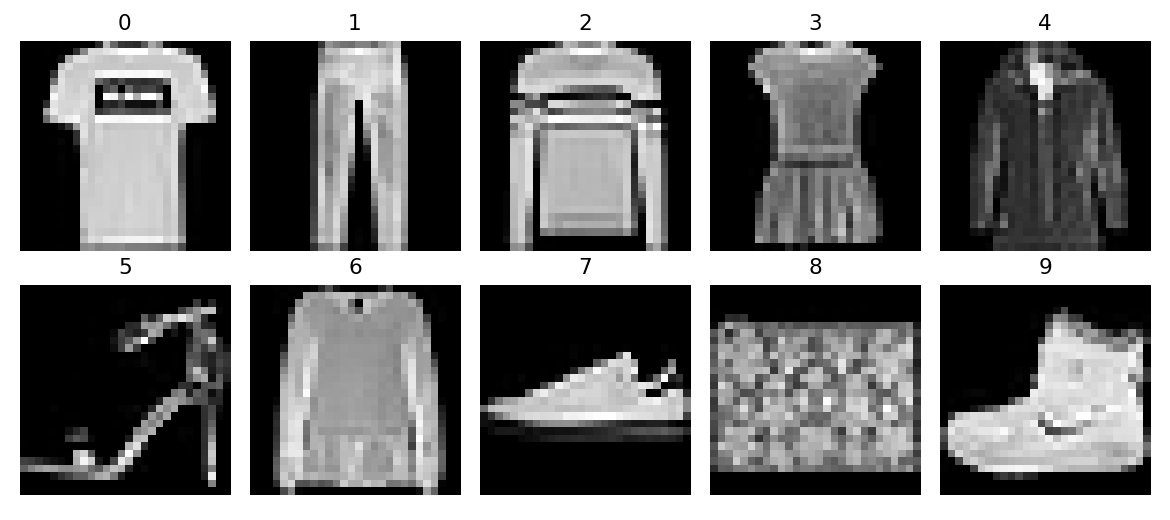

In [3]:
result = run_section("4.2", recompute=RECOMPUTE)
render_result(result)

## 4.3 — Base Classification Model (3 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 179 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. Denote by𝐿v the validation loss, and let𝐿qv be its quick and dirty estimate computed
by the loss function averaging in this section. Lastly, denote by𝑙bv the loss on the last
minibatch. Express𝐿v in terms of𝐿qv,𝑙bv, and the sample and minibatch sizes.
2. Show that the quick and dirty estimate𝐿qv is unbiased. That is, show that𝐸[𝐿v] =
𝐸[𝐿qv]. Why would you still want to use𝐿v instead?
3. Given a multiclass classification loss, denoting by𝑙(𝑦,𝑦′) the penalty of estimating
𝑦′ when we see𝑦 and given a probabilty𝑝(𝑦 | 𝑥), formulate the rule for an optimal
selection of𝑦′. Hint: express the expected loss, using𝑙 and𝑝(𝑦|𝑥).
</pre>
</details>


### Câu 1

Gọi N số mẫu, B số batch, m batch size chuẩn, b=N−(B−1)m là cỡ batch cuối.
Lq là trung bình không trọng số các batch mean; l_last là mean batch cuối.
Tổng loss các batch đầy là `m(B·Lq−l_last)`; tổng cuối `b·l_last`.
Do đó **Lv=[mB·Lq−(m−b)l_last]/N**. Khi b=m thì Lv=Lq.
Notebook kiểm tra với N=11, m=4, b=3.

### Câu 2

Nếu thứ tự mẫu là hoán vị ngẫu nhiên độc lập với loss, mọi batch mean đều có
kỳ vọng bằng mean toàn tập. Vậy E[Lq]=E[Lv]. Nhưng với một thứ tự cố định,
Lq có thể lệch và phương sai lớn hơn vì vài mẫu cuối có trọng số cao hơn.
Lv cân theo số mẫu cho giá trị chính xác của tập đó và không phụ thuộc cách chia batch.
Nếu dữ liệu không shuffle và batch cuối khác phân phối, không mặc định Lq unbiased.

### Câu 3

Chọn `yhat=argmin[a] Σ_y p(y|x) l(y,a)` để tối thiểu expected loss.
Với 0–1 loss là argmax xác suất. Khi chi phí sai khác nhau, quyết định có thể
khác lớp nhiều khả năng nhất; cần loss/cost matrix phù hợp bài toán.

In [4]:
result = run_section("4.3", recompute=RECOMPUTE)
render_result(result)

**batch_average**

,n,batch_size,last_batch_size,quick_mean,weighted_mean,corrected_mean
0,11,4,3,5.333333,5.0,5.0


## 4.4 — Softmax from Scratch (5 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 184 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. Inthissection,wedirectlyimplementedthesoftmaxfunctionbasedonthemathematical
definitionofthesoftmaxoperation. Asdiscussedin Section4.1 thiscancausenumerical
instabilities.
1. Test whethersoftmax still works correctly if an input has a value of100.
2. Test whethersoftmax still works correctly if the largest of all inputs is smaller than
−100?
3. Implement a fix by looking at the value relative to the largest entry in the argument.
2. Implement a cross_entropy function that follows the definition of the cross-entropy
loss function˝𝑖𝑦𝑖 log ˆ𝑦𝑖.
1. Try it out in the code example of this section.
2. Why do you think it runs more slowly?
3. Should you use it? When would it make sense to?
4. What do you need to be careful of? Hint: consider the domain of the logarithm.
3. Is it always a good idea to return the most likely label? For example, would you do this
for medical diagnosis? How would you try to address this?
4. Assume that we want to use softmax regression to predict the next word based on some
features. What are some problems that might arise from a large vocabulary?
5. Experiment with the hyperparameters of the code in this section. In particular:
1. Plot how the validation loss changes as you change the learning rate.
2. Do the validation and training loss change as you change the minibatch size? How
large or small do you need to go before you see an effect?
</pre>
</details>


### Câu 1

Notebook chạy logits [100,101,102] và [−101,−102,−103] ở FP32. Exp trực tiếp
có thể tràn hoặc underflow, sinh NaN/đáp án sai do subnormal. Sửa bằng trừ max
mỗi hàng rồi exp/normalize; để tính loss dùng logsumexp cho ổn định hơn nữa.

### Câu 2

Cross-entropy đầy đủ là **−Σᵢ yᵢ log pᵢ** (cần dấu âm; bản in câu hỏi bỏ dấu âm).
Notebook thực hiện bản one-hot và đối chiếu với fused/index CE trên cùng logits.
Dense one-hot cần thao tác trên mọi lớp, thường tốn bộ nhớ/thao tác hơn gather nhãn
nguyên, nhưng tốc độ cụ thể phải đo; bảng có benchmark sau warm-up.
Dense CE hữu ích với soft labels/label smoothing/distillation. Cẩn thận p=0,
log 0 và biểu thức 0·(−∞) gây NaN; dùng logits và log_softmax thay vì nhân trực tiếp.

### Câu 3

Không phải lúc nào argmax cũng tối ưu: có bài toán chi phí false negative và false
positive khác nhau. Dùng expected cost, ngưỡng theo chi phí, hiệu chuẩn xác suất
hoặc cơ chế từ chối/chuyển kiểm tra. Đây là trả lời nguyên tắc phân loại, không
đưa ra ngưỡng chẩn đoán y khoa cụ thể.

### Câu 4

Vocabulary lớn làm logits/normalization và ma trận trọng số đầu ra lớn, lớp hiếm
ít dữ liệu, tăng thời gian và RAM. Có thể dùng subword, tying embeddings,
sampled/hierarchical/adaptive softmax tùy mục tiêu. Sampling khi train không luôn
cho đúng normalization tại inference; phải phân biệt xác suất chuẩn hóa và điểm xếp hạng.

### Câu 5

Notebook huấn luyện bản scratch (W,b và phép tính logits/CE rõ ràng) với
LR=0.01/0.1/1, batch mặc định 256, 10 epoch; sau đó batch=32/1024 với LR=0.1.
Vẽ validation loss theo epoch và ghi cả train loss/accuracy. Batch nhỏ làm nhiều
bước cập nhật hơn mỗi epoch; không coi so sánh cùng epoch là cùng số bước hay thời gian.
Kết luận lấy từ bảng kết quả đo, không đặt trước một LR luôn tốt nhất.

Dense one-hot CE=2.820356; fused/index CE=2.820356; negative sign is required.


**softmax_stability**

,logits,naive,stable
0,"[100.0, 101.0, 102.0]","[nan, nan, nan]","[0.09003057330846786, 0.2447284758090973, 0.66..."
1,"[-101.0, -102.0, -103.0]","[0.6666666865348816, 0.2666666805744171, 0.066...","[0.6652409434318542, 0.2447284758090973, 0.090..."


**cross_entropy_speed**

,implementation,seconds_per_call
0,dense_one_hot,0.000118
1,index_fused,0.000069


**comparison**

,name,epoch,train_loss,val_loss,train_accuracy,val_accuracy,seconds,hidden,lr,batch,activation,dropout,weight_decay,initialization,scratch
0,lr_0.01,10,0.600673,0.621915,0.808300,0.7949,2.759938,(),0.01,256,relu,"(0.0, 0.0)",0.0,default,True
1,lr_0.1,10,0.447767,0.482206,0.847367,0.8334,2.709453,(),0.10,256,relu,"(0.0, 0.0)",0.0,default,True
2,lr_1.0,10,1.029989,1.168726,0.844633,0.8268,2.788780,(),1.00,256,relu,"(0.0, 0.0)",0.0,default,True
3,batch_32,10,0.401198,0.459343,0.862133,0.8403,7.465420,(),0.10,32,relu,"(0.0, 0.0)",0.0,default,True
4,batch_1024,10,0.524815,0.550116,0.824950,0.8129,2.267557,(),0.10,1024,relu,"(0.0, 0.0)",0.0,default,True


**history**

,name,epoch,train_loss,val_loss,train_accuracy,val_accuracy
0,lr_0.01,1,1.018937,1.030098,0.689000,0.6749
1,lr_0.01,2,0.846818,0.861280,0.735517,0.7215
2,lr_0.01,3,0.769826,0.786400,0.761050,0.7471
3,lr_0.01,4,0.721407,0.738818,0.773250,0.7598
4,lr_0.01,5,0.687764,0.705897,0.785300,0.7705
5,lr_0.01,6,0.662661,0.681835,0.790717,0.7764
6,lr_0.01,7,0.643474,0.663685,0.798317,0.7845
7,lr_0.01,8,0.626158,0.646413,0.801367,0.7878
8,lr_0.01,9,0.612616,0.633689,0.804550,0.7910
9,lr_0.01,10,0.600673,0.621915,0.808300,0.7949


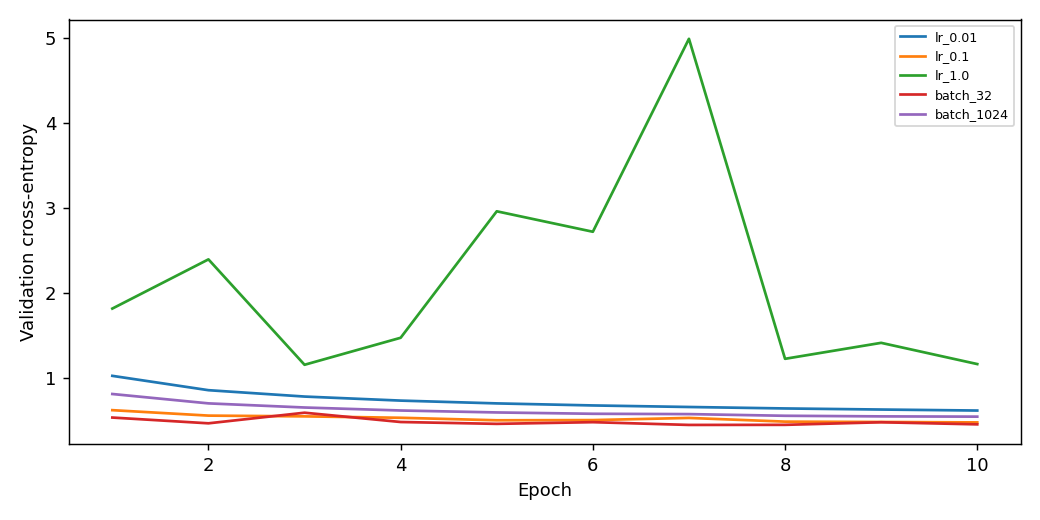

In [5]:
result = run_section("4.4", recompute=RECOMPUTE)
render_result(result)

**Nhận xét từ số đo:** batch_32 có validation loss thấp nhất trong lưới softmax (0.4593), accuracy 84.03%. Batch nhỏ tạo nhiều update hơn mỗi epoch, nên không coi đây là so sánh cùng số bước.

## 4.5 — Concise Softmax (4 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 187 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. Deep learning uses many different number formats, including FP64 double precision
(used extremely rarely), FP32 single precision, BFLOAT16 (good for compressed rep-
resentations), FP16 (very unstable), TF32 (a new format from NVIDIA), and INT8.
Compute the smallest and largest argument of the exponential function for which the
result does not lead to numerical underflow or overflow.
2. INT8 is a very limited format consisting of nonzero numbers from1 to 255. How could
you extend its dynamic range without using more bits? Do standard multiplication and
addition still work?
3. Increasethenumberofepochsfortraining. Whymightthevalidationaccuracydecrease
after a while? How could we fix this?
4. What happens as you increase the learning rate? Compare the loss curves for several
learning rates. Which one works better? When?
</pre>
</details>


### Câu 1

Nếu exp trả về số chuẩn hóa hữu hạn, khoảng x nằm xấp xỉ
`[log(finfo.tiny), log(finfo.max)]`. Khi tính cả subnormal, cận dưới lý thuyết
là `log(tiny*eps)`. Các mốc không phải ngưỡng làm tròn tuyệt đối chính xác;
hardware có thể flush subnormal thành 0. Notebook xuất bảng FP64/FP32/BF16/FP16,
đồng thời tìm ngưỡng bằng `torch.exp` thật trên CPU và kiểm tra số biểu diễn kề
trước/kề sau bằng `nextafter`. Bảng “measured” là ngưỡng của môi trường chạy,
không nhầm log(min_normal) với ngưỡng bắt đầu underflow về đúng 0.
TF32 giữ exponent FP32, giảm mantissa cho một số CUDA matmul, không phải dtype
CPU exp riêng. Số nguyên 8 bit không có khoảng exp dấu phẩy động tương đương;
phải quy định quantization/scale và accumulator.

### Câu 2

Khoảng 1…255 trong đề tương ứng mã unsigned 8 bit bỏ 0, không phải signed INT8
thông thường (−128…127). Mở rộng dynamic range bằng scale/zero-point,
block floating point hoặc log quantization; đánh đổi độ phân giải, không tạo thêm
thông tin. Với log coding, nhân gần thành cộng mã, nhưng cộng giá trị cần log-add;
phép cộng/nhân chuẩn trên mã không còn trực tiếp đúng với giá trị biểu diễn.

### Câu 3

Notebook tăng bản concise lên 20 epoch từ baseline 10. Validation accuracy có thể
giảm do overfitting hoặc dao động tối ưu; không khẳng định chắc chắn sẽ giảm ở
mọi lần chạy. Dùng early stopping theo validation, regularization/augmentation,
LR schedule. Không dùng nhãn test độc lập để quyết định dừng.

### Câu 4

Đối chiếu các LR curve tại 4.4: LR nhỏ có thể tốt khi học đủ lâu nhưng chậm;
LR quá lớn dễ dao động/phân kỳ. Lưới tối ưu phụ thuộc epoch, batch và mô hình.
Để tránh lặp cùng thí nghiệm, mục này dùng lại kết quả LR đã lưu ở 4.4 và có
thêm bản concise 20 epoch riêng.

LR curves reuse section 4.4, avoiding duplicate runs. FP16/BF16 subnormals may be flushed to zero by hardware. TF32 uses FP32 exponent but is a CUDA matmul mode, not CPU exp dtype.


**exp_dynamic_range**

,dtype,log_max_finite,log_min_normal,log_min_subnormal_theoretical
0,torch.float64,709.782713,-708.396419,-744.440072
1,torch.float32,88.722839,-87.336545,-103.278930
2,torch.bfloat16,88.718925,-87.336545,-92.188575
3,torch.float16,11.089866,-9.704061,-16.635532


**exp_measured_boundaries_cpu**

,dtype,smallest_representable_input_with_nonzero_exp,largest_representable_input_with_finite_exp,exp_at_previous_input,exp_at_next_input
0,torch.float64,-745.133219,709.782713,0.0,overflow
1,torch.float32,-103.972076,88.722832,0.0,overflow
2,torch.bfloat16,-92.500000,88.500000,0.0,overflow
3,torch.float16,-17.328125,11.085938,0.0,overflow


**comparison**

,name,epoch,train_loss,val_loss,train_accuracy,val_accuracy,seconds,hidden,lr,batch,activation,dropout,weight_decay,initialization,scratch
0,softmax_longer_20epochs,20,0.425136,0.466817,0.852167,0.8314,2.477683,(),0.1,256,relu,"(0.0, 0.0)",0.0,default,False


**history**

,name,epoch,train_loss,val_loss,train_accuracy,val_accuracy
0,softmax_longer_20epochs,1,0.604847,0.626620,0.807867,0.7926
1,softmax_longer_20epochs,2,0.537251,0.562451,0.823300,0.8127
2,softmax_longer_20epochs,3,0.523166,0.553087,0.819033,0.8061
3,softmax_longer_20epochs,4,0.507585,0.535460,0.828100,0.8175
4,softmax_longer_20epochs,5,0.476946,0.507313,0.838933,0.8258
5,softmax_longer_20epochs,6,0.475629,0.508943,0.837150,0.8188
6,softmax_longer_20epochs,7,0.500281,0.534152,0.826783,0.8113
7,softmax_longer_20epochs,8,0.456604,0.491037,0.843983,0.8268
8,softmax_longer_20epochs,9,0.450921,0.487122,0.847283,0.8299
9,softmax_longer_20epochs,10,0.448106,0.482288,0.847317,0.8340


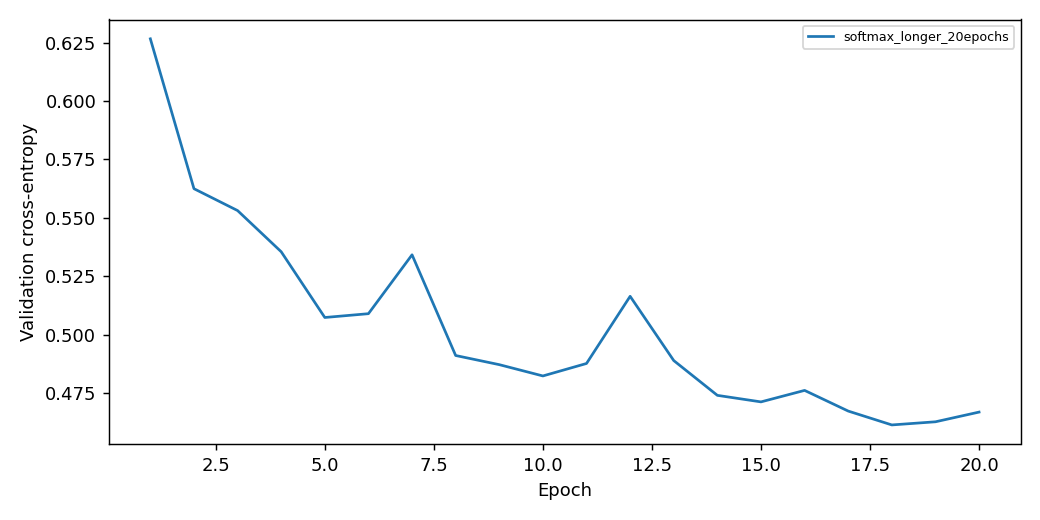

In [6]:
result = run_section("4.5", recompute=RECOMPUTE)
render_result(result)

## 4.6 — Generalization in Classification (4 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 194 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. If we wish to estimate the error of a fixed model𝑓 to within 0.0001 with probability
greater than 99.9%, how many samples do we need?
2. Suppose that somebody else possesses a labeled test setD and only makes available the
unlabeled inputs (features). Now suppose that you can only access the test set labels by
running a model𝑓 (with no restrictions placed on the model class) on each of the un-
labeled inputs and receiving the corresponding error𝜖D(𝑓). How many models would
you need to evaluate before you leak the entire test set and thus could appear to have
error 0, regardless of your true error?
3. What is the VC dimension of the class of fifth-order polynomials?
4. What is the VC dimension of axis-aligned rectangles on two-dimensional data?
</pre>
</details>


### Câu 1

Với classifier cố định, 0–1 error trên mẫu IID, Hoeffding cho
P(|εhat−ε|≥δ)≤2exp(−2nδ²). Đặt δ=0.0001, failure=0.001:
`n≥log(2000)/(2·10⁻⁸)`, lấy trần **380.045.123** là cận đủ (điều kiện
“lớn hơn 99,9%” có thể chọn thêm một mẫu nếu muốn bất đẳng thức nghiêm).
Không phải cỡ mẫu cần thiết tối thiểu trong mọi phân phối.

### Câu 2

Với nhãn nhị phân và oracle trả **exact error**, hỏi một mô hình luôn dự đoán 0,
rồi N mô hình mỗi mô hình chỉ đổi dự đoán ở một xᵢ. Error giảm 1/N nghĩa là
yᵢ=1, tăng 1/N nghĩa là yᵢ=0. Vậy N+1 lần gọi đủ; không khẳng định là tối thiểu.
Đa lớp: baseline lớp 0 và lần lượt đổi sang từng lớp khác, tối đa 1+N(K−1)
lần theo cách đơn giản. Nếu oracle làm tròn/giới hạn truy vấn thì lập luận không còn trực tiếp áp dụng.

### Câu 3

Với classifier 1D `sign(p(x))` và p bậc không quá 5, **VC dimension=6**.
Sáu điểm có thứ tự có tối đa 5 lần đổi dấu, đặt nghiệm giữa những lần đổi dấu
để thực hiện mọi nhãn. Bảy điểm nhãn luân phiên cần 6 nghiệm nên không shatter được.
Nếu “đa thức bậc 5” là đa biến thì cần chỉ rõ số biến, kết quả khác.

### Câu 4

Rectangle song song trục trong R² có **VC dimension=4**. Bốn điểm trái/phải/
trên/dưới hình thoi có thể shatter. Với 5 điểm bất kỳ, chọn tối đa 4 điểm đạt
các cực trị x_min,x_max,y_min,y_max; còn ít nhất một điểm nằm trong bounding box
của các điểm đó. Gán các cực trị positive và điểm còn lại negative thì rectangle
không thực hiện được. Điểm trùng càng không tăng khả năng shatter.

In [7]:
result = run_section("4.6", recompute=RECOMPUTE)
render_result(result)

Hoeffding sufficient n=380,045,123 for epsilon=0.0001, delta=0.001, fixed classifier and IID test draws.
Exact-error test oracle: baseline+N one-coordinate queries recovered labels [0, 1, 1, 0, 1, 0].


## 4.7 — Environment and Distribution Shift (4 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 205 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. What could happen when we change the behavior of a search engine? What might the
users do? What about the advertisers?
2. Implement a covariate shift detector. Hint: build a classifier.
3. Implement a covariate shift corrector.
4. Besides distribution shift, what else could affect how the empirical risk approximates
the risk?
</pre>
</details>


### Câu 1

Đổi thuật toán xếp hạng làm thay đổi thứ người dùng thấy/click; người dùng đổi
truy vấn, nhà quảng cáo đổi giá thầu/nội dung để thích ứng. Log mới do chính hệ
thống tạo ra khác log cũ, có feedback/selection bias. Cần thử nghiệm và theo dõi
chứ không giả định dữ liệu log luôn IID từ một phân phối cố định.

### Câu 2

Notebook tạo hai phân phối covariate tổng hợp và fit domain classifier source=0,
target=1; đánh giá AUC trên hold-out độc lập. AUC cao hơn 0.5 là bằng chứng phân
biệt được hai miền với classifier đó. AUC gần 0.5 không chứng minh hai phân phối
hoàn toàn giống nhau: có thể detector yếu hoặc dữ liệu ít.

### Câu 3

Nếu p_s(y|x)=p_t(y|x), support có chồng lấp và priors miền bằng nhau,
w(x)=p_t(x)/p_s(x)=D(x)/(1−D(x)). Tổng quát phải nhân thêm prior source/target.
Notebook dùng trọng số trên source hold-out để ước lượng mean ở target, so sánh
mean không trọng số, trọng số và target mean thật. Clip weights giảm variance
nhưng thêm bias; xuất effective sample size. Không dùng cách này cho mọi concept shift.

### Câu 4

Cỡ mẫu hữu hạn, phụ thuộc giữa mẫu, nhãn sai, đo đạc sai, selection bias,
model-selection/multiple testing và leakage đều ảnh hưởng empirical risk.
Ngay khi không có shift, train error vẫn có thể lạc quan do thuật toán tối ưu trực tiếp trên train.

In [8]:
result = run_section("4.7", recompute=RECOMPUTE)
render_result(result)

Synthetic covariate shift with shared conditional y=x1+x2. Domain priors are equal; weights=p(target|x)/p(source|x). Correction needs overlap and unchanged p(y|x), not label/concept shift.


**shift_detection_correction**

,heldout_domain_auc,source_mean,importance_weighted_mean,target_mean,effective_sample_size
0,0.788305,-0.024586,1.552833,1.582717,377.952554
